# Introduction to scikit-learn

## Supervised learning

Goal: learn the relationship $y = f(X)$ between:

1. Input data (independent variables, features, covariates, predictors, or $X$ variables)
2. Output data (dependent variable, outcome, target, or $y$ variable)

Two broad types of approaches covered in lectures:

1. **Regression**: numeric output, typically continuous
2. **Classification**: discrete categories or labels

### Machine learning vs. econometrics/statistics

- "Classical" econometrics:
  - Focus on inference and causal questions
  - Causal interpretation requires identification assumptions
  - Emphasis on unbiased and consistent estimators

- Machine learning:
  - Focus on out-of-sample predictive performance
  - Bias-variance trade-off: accept bias when lower variance improves predictions
  - Regularization, penalties, or shrinkage to control model complexity

***
## Outline

### This week

- Linear regression without regularization (OLS)
- Training/test sample splits
- Evaluating model fit
- Multiple regressors and interactions
- Polynomial features
- Pipelines (data preprocessing and estimation)
- Categorical data

***
## Simple linear regression

$$
\begin{aligned}
\text{Econometrics:}\qquad y_i &= \alpha + \beta x_i + \epsilon_i \\
\text{Machine learning:}\qquad y_i &= b + w x_i + \epsilon_i
\end{aligned}
$$

- $\alpha$, $b$: intercept or bias
- $\beta$, $w$: slope or weight
- $\epsilon_i$: error term

#### Linearity assumption

- Linear in coefficients; transformations of $x$ allowed

$$
\begin{aligned}
y_i &= \alpha + \beta_1 x_i + \beta_2 x_i^2 + \epsilon_i \\
\log y_i &= \alpha + \beta \log x_i + \epsilon_i
\end{aligned}
$$

### Estimation of linear models (OLS)

- Minimize sum of squared residuals

$$
L(\alpha,\beta)=\sum_{i=1}^N (y_i-\alpha-\beta x_i)^2
$$

- Estimates, fitted values, residuals

$$
\begin{aligned}
\widehat{\beta}
&=\frac{\widehat{Cov}(y,x)}{\widehat{Var}(x)} \\
\widehat{\alpha}&=\overline{y}-\widehat{\beta}\,\overline{x} \\
\widehat{y}_i&=\widehat{\alpha}+\widehat{\beta}x_i \\
\widehat{\epsilon}_i&=y_i-\widehat{y}_i
\end{aligned}
$$

- Multiple regressors, including a constant

$$
y_i=\mathbf{x}_i'\bm{\beta}+\epsilon_i,\qquad
\widehat{\bm{\beta}}=(\mathbf{X}'\mathbf{X})^{-1}\mathbf{X}'\mathbf{y}
$$

- Matrix expression for theory; packaged solvers for computation

***
### Simple linear regression with scikit-learn

#### Step 1: Generate demo sample

$$
\begin{aligned}
y_i &= \alpha+\beta x_i+\epsilon_i \\
x_i &\sim U(0,10),\qquad
\epsilon_i\stackrel{\text{iid}}{\sim}N(0,\sigma^2) \\
\alpha&=1,\qquad\beta=\tfrac12,\qquad\sigma=0.7
\end{aligned}
$$

- $N=50$; fixed seed for reproducibility

In [24]:
# Imports used in the notebook
import matplotlib.pyplot as plt
import numpy as np

In [25]:
def create_sample(N, alpha, beta, sigma, rng=None):
    """
    Create sample for simple linear regression

    Parameters
    ----------
    N : int
        Sample size
    alpha : float
        Intercept (or bias)
    beta : float
        Slope (or weight)
    sigma : float
        Standard deviation of the error term
    rng : object, optional
        Random number generator

    Returns
    -------
    x : array
        Predictor variable, uniformly distributed on [0, 10]
    y : array
        Outcome variable
    """
    from numpy.random import default_rng

    # Use a fixed seed when no generator is supplied
    if rng is None:
        rng = default_rng(seed=1234)

    # Use x that are uniformly distributed on [0, 10]
    x = rng.uniform(0, 10, size=N)

    # Normally distributed errors
    epsilon = rng.normal(scale=sigma, size=N)

    # Create outcome variable
    y = alpha + beta * x + epsilon

    return x, y

In [26]:
# Sample size
N = 50

# True model parameters
alpha = 1.0
beta = 0.5
sigma = 0.7

# Create sample
x, y = create_sample(N=N, alpha=alpha, beta=beta, sigma=sigma)

#### Step 2: Estimate model

- Fit linear regression with
  [`LinearRegression()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
- `fit()`: estimate coefficients
  - Feature matrix: shape `(N, 1)`, even with one regressor
- `predict()`: predict fitted values using estimated coefficients
- Coefficients: `intercept_` and `coef_`

In [27]:
from sklearn.linear_model import LinearRegression

# Create LinearRegression object
lr = LinearRegression(fit_intercept=True)

# fit() expects a two-dimensional object, convert x to N-by-1 matrix
X = x[:, None]

# Fit model to data
lr.fit(X, y)

# Predict fitted values
yhat = lr.predict(X)

# Extract parameter estimates from LinearRegression object
alpha_hat = lr.intercept_
beta_hat = lr.coef_[0]

print(f'Estimated alpha: {alpha_hat:.3f}')
print(f'Estimated beta: {beta_hat:.3f}')

Estimated alpha: 1.376
Estimated beta: 0.482


#### Step 3: Plot sample and fitted values

In [28]:
def plot_regression(x, y, alpha, beta, alpha_hat, beta_hat, title=None):
    """
    Plot observations, true and fitted regression lines, and residuals.

    Parameters
    ----------
    x : array
        Explanatory variable
    y : array
        Observed response variable
    alpha : float
        True intercept
    beta : float
        True slope
    alpha_hat : float
        Estimated intercept
    beta_hat : float
        Estimated slope
    title : str, optional
        Title for the plot
    """
    import matplotlib.pyplot as plt

    yhat = alpha_hat + beta_hat * x

    _fig, ax = plt.subplots(figsize=(5, 3.5), layout='constrained')

    # Plot observations
    ax.scatter(x, y, s=20, c='none', ec='steelblue', alpha=1.0, lw=0.75, label='y')

    # Connect observed and fitted values
    for i in range(len(x)):
        ax.plot([x[i], x[i]], [y[i], yhat[i]], lw=0.5, ls=':', c='black', alpha=0.9)

    # Plot true relationship
    label = r'$y = \alpha + \beta x$'
    ax.axline((0.0, alpha), slope=beta, lw=1.5, ls='--', c='black', label=label)

    # Plot regression line
    label = r'$\widehat{y} = \widehat{\alpha} + \widehat{\beta} x$'
    ax.axline((0.0, alpha_hat), slope=beta_hat, lw=1.5, c='darkorange', label=label)

    # Add annotations
    ax.set_xlabel('Explanatory variable: x')
    ax.set_ylabel(r'Response variable: y, $\widehat{y}$')
    ax.axhline(alpha_hat, lw=0.5, c='black')
    ax.legend(loc='best')
    ax.set_yticks((alpha_hat,), (r'$\widehat{\alpha}$',))
    ax.set_title(title or 'Simple linear regression')

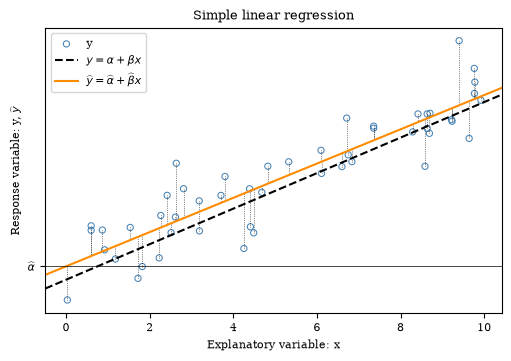

In [29]:
plot_regression(x, y, alpha=alpha, beta=beta, alpha_hat=alpha_hat, beta_hat=beta_hat)

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

1. Write a loop to recreate and re-estimate the model for samples of size 10, 50, 100, 1000, and 10000.
2. Print the estimated values of $\alpha$ and $\beta$. Can you say something about the deviation from the true values as the sample size increases?
</div>
<span style="display: none;">YourTurnEnd</span>

***
### Digression: Machine learning versus econometrics

- scikit-learn: prediction on new data
- [statsmodels](https://www.statsmodels.org/stable/index.html): standard errors, tests, confidence intervals
- Same OLS coefficients for the same sample
- Demo below ready to run

$$
y_i=\alpha+\beta x_i+\epsilon_i
$$

In [30]:
# Sample size
N = 50

# True model parameters
alpha = 1.0
beta = 0.5
sigma = 0.7

# Create sample
x, y = create_sample(N=N, alpha=alpha, beta=beta, sigma=sigma)

# Refit scikit-learn on the same sample used by statsmodels
_ = lr.fit(x[:, None], y)

In [31]:
import statsmodels.api as sm

# Add constant for intercept
X_with_const = sm.add_constant(x)

# Fit OLS regression
model = sm.OLS(y, X_with_const)
results = model.fit()

print(results.summary())
print('statsmodels coefficients:', results.params)
print('scikit-learn coefficients:', lr.intercept_, lr.coef_[0])

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.814
Model:                            OLS   Adj. R-squared:                  0.810
Method:                 Least Squares   F-statistic:                     209.7
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           3.86e-19
Time:                        13:29:40   Log-Likelihood:                -54.171
No. Observations:                  50   AIC:                             112.3
Df Residuals:                      48   BIC:                             116.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.3762      0.204      6.758      0.0

The fitted model contains the following attributes:

- `results.params`: coefficients
- `results.bse`: standard errors
- `results.conf_int(alpha=0.05)`: 95% confidence intervals


<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Estimate the statsmodels regression for samples of size 10, 20, 50, 100, 1000,
and 10000.

1. Use `create_sample()` with $\sigma=4.0$ and a fixed seed 1234.
2. For each sample, print the slope's standard error (`results.bse[1]`) and 95% confidence interval (`results.conf_int()[1]`).
3. How do the standard errors change, and which intervals exclude zero?

</div>
<span style="display: none;">YourTurnEnd</span>

***
### Training and test samples

- Training sample: estimate model and guide model specification / hyperparameter tuning
- Test sample: evaluate predictions on held-out data
- Good training fit alone: no guarantee of good test predictions (problem of overfitting)

#### Example: Ames housing data

- `ames_houses_synthetic.csv`: house characteristics plus synthetic prices
- Target: `SalePrice`, thousand USD
- Features: `LivingArea`, `YearBuilt`, `LotArea`, `BuildingType`
- Already restricted to living area ≤ 300 m² and lot area ≤ 2,500 m²

##### Estimation steps

1. Load and inspect data
2. Define features and target variable
3. Split training and test samples
4. Fit Model 1 (living area)
5. Plot sample and fitted relationship
6. Predict and plot errors
7. Evaluate model fit on test sample

##### Step 1: Load and inspect data

In [32]:
# Use the local data/ directory
DATA_PATH = '../../data'

# Load data directly from GitHub
# DATA_PATH = 'https://raw.githubusercontent.com/richardfoltyn/TECH6-H26/main/data'

In [33]:
import pandas as pd

file = f'{DATA_PATH}/ames_houses_synthetic.csv'
df_ames = pd.read_csv(file)

# List columns present in DataFrame
df_ames.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 2881 entries, 0 to 2880
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SalePrice     2881 non-null   float64
 1   LivingArea    2881 non-null   float64
 2   LotArea       2881 non-null   float64
 3   YearBuilt     2881 non-null   int64  
 4   BuildingType  2881 non-null   str    
dtypes: float64(3), int64(1), str(1)
memory usage: 112.7 KB


##### Step 2: Define features and target variable

- Start with living area
- Scale for estimation; original units in plots

$$
A_i=LivingArea_i/100
$$

- Coefficient units: thousand USD per additional 100 m²

In [34]:
# Create a new variable A that is the living area in hundreds of square meters
df_ames['A'] = df_ames['LivingArea'] / 100

# Define features and target variable
features = ['A']
target = 'SalePrice'

# Create separate Series / DataFrames for target and features
y = df_ames[target]
X = df_ames[features]

##### Step 3: Split training and test samples

- Split data with
  [`train_test_split()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
- Test fraction: 0.3
- Seed: `random_state=1234`

In [35]:
from sklearn.model_selection import train_test_split

# fraction of data used for test sample
test_size = 0.3

# Split into training / test samples
X_train1, X_test1, y_train, y_test = train_test_split(
    X,
    y,
    test_size=test_size,  # Fraction used for test sample
    random_state=1234,  # Seed for random number generator
)

In [36]:
# Create DataFrames for training and test sets with original features
# (used for diagnostic plots)
df_train = df_ames.loc[X_train1.index, :]
df_test = df_ames.loc[X_test1.index, :]

In [37]:
df_train[['SalePrice', 'LivingArea', 'LotArea', 'YearBuilt']].corr()['SalePrice']

SalePrice     1.000000
LivingArea    0.784587
LotArea       0.424788
YearBuilt     0.653875
Name: SalePrice, dtype: float64

##### Step 4: Fit **Model 1** (living area)

- Living area: strongest training correlation

$$
SalePrice_i=\alpha+\beta_A A_i+\epsilon_i
$$

- $\beta_A$: price change per 100 m²
- Slope per m²: $\beta_A/100$

In [38]:
# Fit model on training sample
model1 = LinearRegression()
model1.fit(X_train1, y_train)

# Extract estimated parameters
intercept = model1.intercept_
slope = model1.coef_[0]

print('Regression coefficients')
print(f'  Intercept: {intercept:.2f}')
print(f'  Slope per 100m²: {slope:.2f}')

Regression coefficients
  Intercept: 9.38
  Slope per 100m²: 122.15


##### Step 5: Plot sample and fitted relationship

In [39]:
def plot_regression_line(X_train, y_train, X_test, y_test, intercept, slope):
    """
    Plot training and test data with fitted regression line.

    Parameters
    ----------
    X_train : array-like
        Training sample living areas in m²
    y_train : Series
        Training sample target variable
    X_test : array-like
        Test sample living areas in m²
    y_test : Series
        Test sample target variable
    intercept : float
        Estimated intercept of the regression model
    slope : float
        Estimated slope of the regression model (per 100m²)
    """
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), layout='constrained')

    # Plot training data
    axes[0].scatter(X_train, y_train, s=15, c='none', ec='steelblue', alpha=0.8, lw=0.5)

    # Plot test data
    axes[1].scatter(X_test, y_test, s=15, c='none', ec='darkorange', alpha=1.0, lw=0.5)

    # Plot regression line and annotations
    label = r'$\widehat{y} = \widehat{\alpha} + \widehat{\beta} x$'
    titles = ['Training sample', 'Test sample']
    for i, ax in enumerate(axes):
        ax.axline((0.0, intercept), slope=slope / 100, lw=1.5, c='black', label=label)

        # Add annotations
        ax.set_xlabel('Living area in $m^2$')
        ax.set_ylabel(r'Sale price in thousand $')
        ax.set_title(titles[i])
        ax.legend(loc='best')

    fig.suptitle('Fitted simple linear regression', fontweight='bold')

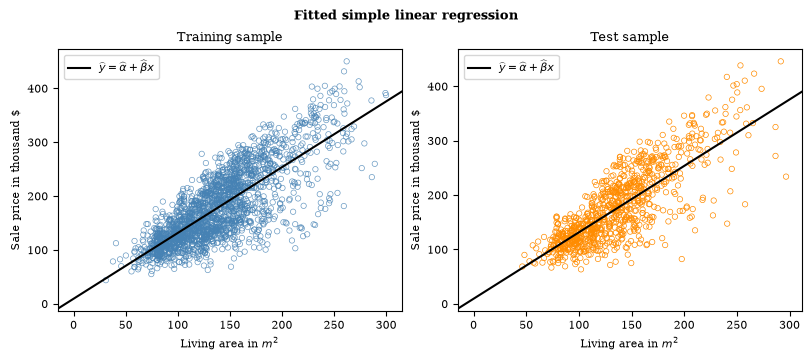

In [40]:
plot_regression_line(
    df_train['LivingArea'], y_train, df_test['LivingArea'], y_test, intercept, slope
)

##### Step 6: Predict and plot errors

$$
e_i=y_i-\widehat{y}_i
   =y_i-\widehat{\alpha}-\widehat{\beta}_A A_i
$$

- Positive error: underprediction
- Negative error: overprediction
- Training errors: spot patterns the model misses

In [41]:
# Compute training predictions and errors for the plots
yhat_train1 = model1.predict(X_train1)
errors_train1 = y_train - yhat_train1

In [42]:
def plot_errors(x, errors, xlabel, title=None, ylabel=None, ax=None, legend=True):
    """
    Plot errors and bin means.

    Parameters
    ----------
    x : array-like
        Variable shown on the x-axis.
    errors : array-like
        Prediction error for each observation.
    xlabel : str
        Label for the x-axis.
    title : str, optional
        Title identifying the model or sample.
    ylabel : str, optional
        Label for the y-axis.
    ax : axes, optional
        Matplotlib axes on which to draw the plot.
    legend : bool, optional
        Whether to show the legend. Default is True.
    """
    # Create a new figure and axes if none are provided
    if ax is None:
        _fig, ax = plt.subplots(figsize=(5, 3.5), layout='constrained')

    # Plot errors for each observation
    ax.scatter(x, errors, s=15, c='none', ec='steelblue', alpha=0.4, label='Errors')
    # Add horizontal line at y=0 to indicate zero error
    ax.axhline(0, c='black', lw=0.75, ls='--')

    # Convert to arrays so pandas does not align different observation indices.
    df_plot = pd.DataFrame({'x': np.asarray(x), 'error': np.asarray(errors)})
    bins = pd.cut(df_plot['x'], bins=8)
    # Compute means of x and errors within each bin
    df_means = df_plot.groupby(bins, observed=True)[['x', 'error']].mean()
    # Plot means of x and errors within each bin
    xbin, ybin = df_means['x'], df_means['error']
    ax.plot(xbin, ybin, marker='o', c='black', lw=1.5, ms=5, label='Bin means')

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel or 'Training error (thousand USD)')
    if title is not None:
        ax.set_title(title, fontweight='bold')
    if legend:
        ax.legend(loc='best')

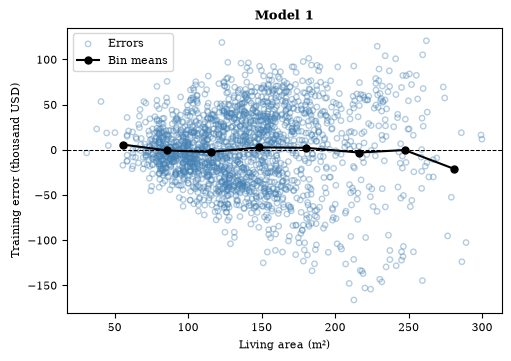

In [43]:
plot_errors(df_train['LivingArea'], errors_train1, 'Living area (m²)', 'Model 1')

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Recreate Model 1's training error plot using `yhat_train1` on the x-axis.
Why does it look almost identical to the plot against living area?
</div>
<span style="display: none;">YourTurnEnd</span>

##### Step 7: Evaluate model fit

- MSE: average squared prediction error, computed with
  [`mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html)

$$
MSE=\frac{1}{N}\sum_{i=1}^N (y_i-\widehat{y}_i)^2
$$

- RMSE: same units as $y$, here thousand USD; computed with
  [`root_mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.root_mean_squared_error.html)

$$
RMSE=\sqrt{MSE}
$$

- $R^2$: fit relative to the evaluation sample's mean, computed with
  [`r2_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html)

$$
R^2=1-\frac{MSE}{N^{-1}\sum_{i=1}^N(y_i-\overline{y})^2}
$$

- $R^2=1$: perfect predictions; $R^2=0$: sample-mean benchmark
- OLS with intercept: training $R^2$ between 0 and 1
- Test $R^2$ can be negative

In [44]:
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error

# Compute test predictions for the performance metrics
yhat_test1 = model1.predict(X_test1)

# Compute Model 1 test MSE
mse = mean_squared_error(y_test, yhat_test1)
print(f'Model 1 test MSE: {mse:.1f} (thousand USD)²')

Model 1 test MSE: 1720.9 (thousand USD)²


<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Compute Model 1's test RMSE with `root_mean_squared_error()` and $R^2$
with `r2_score()`. 

- Interpret both values, including the units of RMSE.
- What benchmark does $R^2=0$ represent in this test sample?

</div>
<span style="display: none;">YourTurnEnd</span>

In [45]:
# Keep a comparison table and add one row after fitting each model.

# Compute test performance metrics for Model 1
rmse_test1 = root_mean_squared_error(y_test, yhat_test1)
r2_test1 = r2_score(y_test, yhat_test1)

df_results = pd.DataFrame(
    {'RMSE': [rmse_test1], 'R²': [r2_test1]}, index=pd.Index(['Model 1'], name='Model')
)
df_results

,RMSE,R²
Model,,
Model 1,41.484218,0.644477


***
## Multiple linear regression

### Data with several explanatory variables

$$
y_i=\mathbf{x}_i'\bm{\beta}+\epsilon_i
$$

- Feature vector $\mathbf{x}_i$; coefficient vector $\bm{\beta}$
- First check: Model 1 training errors against construction year

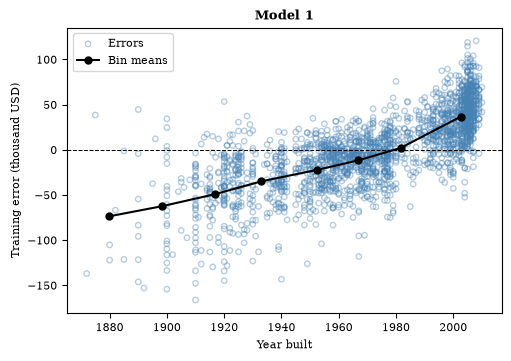

In [46]:
plot_errors(df_train['YearBuilt'], errors_train1, 'Year built', 'Model 1')

#### **Model 2:** Add construction year

##### Step 1: Prepare features

- Model 2: living area and construction year

$$
\begin{aligned}
T_i&=(YearBuilt_i-1970)/10 \\
SalePrice_i&=\alpha+\beta_A A_i+\beta_T T_i+\epsilon_i
\end{aligned}
$$

- $T_i$: decades since 1970
- $\beta_T$: price difference for a house built a decade later, same living area
- $\beta_A$: area effect, same construction year

In [ ]:
# T measures decades since 1970
df_ames['T'] = (df_ames['YearBuilt'] - 1970) / 10

In [ ]:
# Define features for Model 2
features2 = ['A', 'T']

# Create new DataFrames for training and test samples with the new features
X_train2 = df_ames.loc[X_train1.index, features2]
X_test2 = df_ames.loc[X_test1.index, features2]

##### Step 2: Fit Model 2

In [ ]:
# TODO: Create model2 and fit it to X_train2, y_train
# TODO: Extract intercept2 and coef2

print(f'Model 2 intercept: {intercept2:.2f}')
print('Model 2 coefficients (A, T):', coef2)

##### Step 3: Predict training errors

In [ ]:
# TODO: Compute predicted values yhat_train2
# TODO: Compute training errors errors_train2

##### Step 4: Compare training errors

- `plot_error_comparison()`: precomputed errors, models in rows, variables in columns

In [ ]:
def plot_error_comparison(errors_by_model, model_names, variables, ylim=None):
    """
    Compare training errors across models and (explanatory) variables.

    Parameters
    ----------
    errors_by_model : list of array-like
        Training prediction errors for each model.
    model_names : list of str
        Titles for the model rows.
    variables : dict
        Axis labels mapped to numeric training variables.
    ylim : tuple, optional
        Common vertical error limits; autoscale when omitted.
    """
    xlabels = list(variables)
    xvalues = list(variables.values())
    nrows = len(errors_by_model)
    ncols = len(xlabels)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(4 * ncols, 3 * nrows),
        sharex='col',  # Share x-axis only within columns
        sharey=True,  # Share y-axis across all subplots
        squeeze=False,  # Keep axes two-dimensional even with one row or column
        layout='constrained',
    )

    for i, errors in enumerate(errors_by_model):
        err = np.asarray(errors)
        for j in range(ncols):
            ax = axes[i, j]
            plot_errors(
                xvalues[j], err, xlabels[j], model_names[i], ax=ax, legend=False
            )

    if ylim is not None:
        axes[0, 0].set_ylim(ylim)

    return fig, axes

In [ ]:
fig, axes = plot_error_comparison(
    [errors_train1, errors_train2],
    ['Model 1', 'Model 2'],
    variables={
        'Living area (m²)': df_train['LivingArea'],
        'Year built': df_train['YearBuilt'],
    },
    ylim=(-150, 150),
)

In [ ]:
# Compute model 2 predictions for test sample
yhat_test2 = model2.predict(X_test2)

# Compute test performance metrics for Model 2
rmse_test2 = root_mean_squared_error(y_test, yhat_test2)
r2_test2 = r2_score(y_test, yhat_test2)

# Add model 2 results to the results DataFrame
df_results.loc['Model 2'] = [rmse_test2, r2_test2]
df_results

#### **Model 3:** Add lot area

##### Step 1: Inspect existing errors

- Next check: Model 2 training errors against lot area

In [ ]:
plot_errors(df_train['LotArea'], errors_train2, 'Lot Area (m²)', 'Model 2')

##### Step 2: Prepare features

- Model 3: add lot area

$$
\begin{aligned}
L_i&=LotArea_i/1000 \\
SalePrice_i&=\alpha+\beta_A A_i+\beta_T T_i+\beta_L L_i+\epsilon_i
\end{aligned}
$$

- $\beta_L$: price change per 1,000 m² of lot area
- Hold living area and construction year fixed

In [ ]:
# Add (scaled) lot area as an additional regressor
df_ames['L'] = df_ames['LotArea'] / 1000

# Define features for Model 3
features3 = ['A', 'T', 'L']

# Create training and test DataFrames for Model 3
X_train3 = df_ames.loc[X_train1.index, features3]
X_test3 = df_ames.loc[X_test1.index, features3]

##### Step 3: Fit Model 3

In [ ]:
# Fit Model 3 on training sample
model3 = LinearRegression()
model3.fit(X_train3, y_train)

print(f'Model 3 intercept: {model3.intercept_:.2f}')
print('Model 3 coefficients (A, T, L):', model3.coef_)

##### Step 4: Compare training errors

In [ ]:
# TODO: Compute training errors errors_train3 from model3 and X_train3

fig, axes = plot_error_comparison(
    [errors_train2, errors_train3],
    ['Model 2', 'Model 3'],
    variables={
        'Living area (m²)': df_train['LivingArea'],
        'Year built': df_train['YearBuilt'],
        'Lot area (m²)': df_train['LotArea'],
    },
    ylim=(-150, 150),
)

##### Step 5: Evaluate test performance

In [ ]:
# Compute test predictions for Model 3
yhat_test3 = model3.predict(X_test3)

# Compute test performance metrics for Model 3
rmse_test3 = root_mean_squared_error(y_test, yhat_test3)
r2_test3 = r2_score(y_test, yhat_test3)

# Tabulate test performance metrics for Models 1-3
df_results.loc['Model 3'] = [rmse_test3, r2_test3]
df_results

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Fit a model using living area $A_i$ and lot area $L_i$ as regressors, keeping the same training and test samples.

- Compute its test RMSE and compare it with Models 2 and 3. 
- Use `plot_error_comparison()` to compare its training errors against year built
  with those of Model 3.
- Does lot area compensate for leaving out construction year? Which construction periods does the reduced model tend to overpredict or underpredict?

</div>
<span style="display: none;">YourTurnEnd</span>

***
### Creating polynomial features

- Additional features: Interactions from existing variables
- Linear in coefficients, even with nonlinear features

$$
y_i=\alpha+\beta_0x_i+\beta_1x_i^2+\beta_2x_i^3+\epsilon_i
$$

#### **Model 4:** Living area × construction year

##### Step 1: Create interaction

$$
SalePrice_i=\alpha+\beta_A A_i+\beta_T T_i+\beta_L L_i
+\beta_{AT}A_iT_i+\epsilon_i
$$

- Area effect per 100 m², holding year and lot area fixed

$$
\frac{\partial \widehat{SalePrice}_i}{\partial A_i}
=\widehat{\beta}_A+\widehat{\beta}_{AT}T_i
$$

- Area slope can differ by construction year

In [ ]:
# Create interaction term
df_ames['AT'] = df_ames['A'] * df_ames['T']

# Define features for Model 4
features4 = ['A', 'T', 'L', 'AT']

# Create training and test DataFrames for Model 4
X_train4 = df_ames.loc[X_train1.index, features4]
X_test4 = df_ames.loc[X_test1.index, features4]

##### Step 2: Fit Model 4

In [ ]:
# Fit Model 4 on training sample
model4 = LinearRegression()
model4.fit(X_train4, y_train)
coef4 = model4.coef_

print('Model 4 coefficients (A, T, L, AT):', coef4)

##### Step 3: Interpret area effects

- Marginal effects for houses built in 1930, 1970, and 2010

In [ ]:
years = np.array([1930, 1970, 2010])

# Compute slopes (marginal effects) for given years using the
# formula: slope = beta_A + beta_AT * (YearBuilt - 1970) / 10
slopes = coef4[0] + coef4[3] * (years - 1970) / 10

df_slopes = pd.DataFrame(
    {'Year built': years, 'Price increase per 100m² (thousand USD)': slopes}
)
df_slopes.round(1)

##### Step 4: Predict and score

In [ ]:
# Compute training errors for Model 4
errors_train4 = y_train - model4.predict(X_train4)

# Predict test values for Model 4
yhat_test4 = model4.predict(X_test4)

# Compute test performance metrics for Model 4
rmse_test4 = root_mean_squared_error(y_test, yhat_test4)
r2_test4 = r2_score(y_test, yhat_test4)

# Add model 4 results to the results DataFrame
df_results.loc['Model 4'] = [rmse_test4, r2_test4]
df_results

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Already fitted Models 3 and 4; houses built before 1950.

- Test houses: compute each model's RMSE.
- Training houses: compare errors against living area with `plot_error_comparison()`.
- Does adding the interaction reduce the trend in the bin means?

</div>
<span style="display: none;">YourTurnEnd</span>

#### **Model 5:** Quadratic polynomial

##### Step 1: Create polynomial features

- Create polynomial terms with
  [`PolynomialFeatures()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)
- Two variables, degree 2: squares and pairwise interaction

$$
p(x,z)=\beta_0+\beta_1x+\beta_2z+\beta_3x^2+\beta_4xz+\beta_5z^2
$$

- Model 5: degree 2 in $A,L,T$, ten coefficients

$$
\begin{aligned}
p_2(A_i,L_i,T_i)
&=\alpha+\beta_A A_i+\beta_L L_i+\beta_T T_i \\
&\quad+\beta_{AA}A_i^2+\beta_{AL}A_iL_i+\beta_{AT}A_iT_i \\
&\quad+\beta_{LL}L_i^2+\beta_{LT}L_iT_i+\beta_{TT}T_i^2 \\
SalePrice_i&=p_2(A_i,L_i,T_i)+\epsilon_i
\end{aligned}
$$

- PolynomialFeatures:
  - `include_bias=True`: constant feature included
  - `powers_`: exponents; `get_feature_names_out()`: labels
- Then `LinearRegression(fit_intercept=False)`: only one intercept

In [ ]:
# TODO: Import PolynomialFeatures

# List of continuous variables used to build polynomial features
CONT_VARIABLES = ['A', 'L', 'T']
df_train5 = df_ames.loc[X_train1.index, CONT_VARIABLES]
df_test5 = df_ames.loc[X_test1.index, CONT_VARIABLES]

# TODO: Create poly object
# TODO: Fit-transform df_train5 into X_train5

# TODO: Inspect poly.powers_

##### Step 2: Fit Model 5

- Ten columns: `1, A, L, T, A², AL, AT, L², LT, T²`
- First coefficient: constant feature
- Separate `intercept_`: zero

In [ ]:
# TODO: Create model5 with fit_intercept=False; fit to X_train5, y_train
# TODO: Extract coef5 from model5
# TODO: Get labels from poly.get_feature_names_out(CONT_VARIABLES)

pd.DataFrame({'Coef': coef5}, index=labels)

##### Step 3: Predict and plot errors

In [ ]:
# Compute training errors for Model 5
errors_train5 = y_train - model5.predict(X_train5)

fig, axes = plot_error_comparison(
    [errors_train4, errors_train5],
    ['Model 4', 'Model 5'],
    variables={
        'Living area (m²)': df_train['LivingArea'],
        'Year built': df_train['YearBuilt'],
        'Lot area (m²)': df_train['LotArea'],
    },
    ylim=(-150, 150),
)

##### Step 4: Transform test data and evaluate

- Reuse fitted `poly`; `transform()` on test data
- Test scores: compare predictions on new houses

In [ ]:
# TODO: Transform df_test5 into X_test5 using poly
# TODO: Predict yhat_test5 on X_test5

In [ ]:
# Compute test performance metrics for Model 5
rmse_test5 = root_mean_squared_error(y_test, yhat_test5)
r2_test5 = r2_score(y_test, yhat_test5)
df_results.loc['Model 5'] = [rmse_test5, r2_test5]
df_results

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Fit a separate polynomial model with `interaction_only=True`, keeping `degree=2` and `include_bias=True`. 

- Reuse `df_train5`, `df_test5`, `y_train`, and `y_test` so that the training and test samples stay the same. 
- Fit the regression with `LinearRegression(fit_intercept=False)`.
- Use `get_feature_names_out(CONT_VARIABLES)` on the new transformer to inspect its
  features. Which terms have disappeared compared with Model 5?
- Compute the new model's test RMSE and compare it with Model 5. Do the squared terms improve prediction beyond the pairwise interactions?

</div>
<span style="display: none;">YourTurnEnd</span>

***
### Using scikit-learn pipelines

- Chain transformations and final estimator
- Explicitly named steps with
  [`Pipeline()`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
- Automatically named steps with
  [`make_pipeline()`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html)
- Intermediate steps: apply transformations (polynomials, scaling, etc.)
- Final step: regression
- Same Model 5 formula and intercept convention

#### Step 1: Create pipeline

In [ ]:
# TODO: Import Pipeline from sklearn.pipeline

# TODO: Create pipe with named steps poly and lr

#### Step 2: Fit pipeline

- Inputs: original `df_train5`, `y_train`
- Access fitted steps through `named_steps`

In [ ]:
# TODO: Fit pipe to df_train5, y_train
# TODO: Get labels_pipe from the fitted poly step
# TODO: Extract coef_pipe from the fitted lr step

pd.DataFrame({'Coef': coef_pipe}, index=labels_pipe)

#### Simpler alternative

- `make_pipeline()`: pass transformer and estimator
- Default names: lowercase class names

In [ ]:
# TODO: Import make_pipeline from sklearn.pipeline
# TODO: Recreate pipe with make_pipeline(), using the same settings
# TODO: Fit pipe to df_train5, y_train
# TODO: Inspect pipe.named_steps
# TODO: Predict yhat_test_pipe on df_test5 before changing the pipeline

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Change the degree-2 pipeline to `include_bias=False` and `fit_intercept=True`. 

- Fit on the same training data; compare test predictions with `yhat_test_pipe`
  using `np.allclose()`.
- Why do both intercept conventions give the same
predictions?
</div>
<span style="display: none;">YourTurnEnd</span>

***
## Dealing with categorical data

- `BuildingType`: `Single-family`, `Townhouse`, `Two-family`
- Categories with no natural numeric order

In [ ]:
# Tabulate the number of observations in each building type category
df_train['BuildingType'].value_counts().sort_index()

#### One-hot encoding

- Create one binary indicator per category with
  [`OneHotEncoder()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- `categories`: explicit category order
- `sparse_output=False`: ordinary array

In [ ]:
# TODO: Import OneHotEncoder from sklearn.preprocessing

building_uniq = list(np.sort(df_train['BuildingType'].unique()))

# TODO: Create enc with categories=[building_uniq], sparse_output=False
# TODO: Fit-transform df_train[['BuildingType']] into building_dummies
# TODO: Extract building_labels from enc.categories_[0]

#### Model 6: Polynomial plus building-type dummies

##### Step 1: Prepare dummy variables

$$
\begin{aligned}
SalePrice_i
&=p_2(A_i,L_i,T_i)
+\gamma_{TH}D_{TH,i}+\gamma_{TF}D_{TF,i}+\epsilon_i \\
D_{TH,i}&=\mathbf{1}\{BuildingType_i=\text{Townhouse}\} \\
D_{TF,i}&=\mathbf{1}\{BuildingType_i=\text{Two-family}\}
\end{aligned}
$$

- $p_2$: Model 5's quadratic polynomial
- Reference: single-family houses
- Dummy coefficients: price differences, holding $A,L,T$ fixed
- Fit encoder on training data; transform test data

In [ ]:
# TODO: Create OneHotEncoder instance enc6, drop 'Single-family'
# TODO: Fit-transform training BuildingType into dummies_train
# TODO: Transform test BuildingType into dummies_test

X_train6 = np.hstack((X_train5, dummies_train))
X_test6 = np.hstack((X_test5, dummies_test))

##### Step 2: Fit Model 6

In [ ]:
# TODO: Create model6 with fit_intercept=False; fit to X_train6, y_train
# TODO: Extract coef6 from model6

In [ ]:
# Get coefficient labels for polynomial features
labels6 = list(poly.get_feature_names_out(CONT_VARIABLES))
# Get coefficient labels for building-type dummies
labels6 += list(enc6.get_feature_names_out(['BuildingType']))
pd.DataFrame({'Coef': coef6}, index=labels6)

##### Step 3: Compare errors by building type

- Compare Models 5 and 6 on the training sample
- Group means: systematic overprediction or underprediction
- Positive errors: underprediction

In [ ]:
def plot_errors_by_building_type(errors_by_model, model_names, df_train):
    """
    Compare training errors across models and building types.

    Parameters
    ----------
    errors_by_model : list of array-like
        Training errors for each model.
    model_names : list of str
        Titles for the model columns.
    df_train : DataFrame
        Training dataset.
    """
    ncols = len(errors_by_model)
    building_uniq = list(np.sort(df_train['BuildingType'].unique()))
    ngroups = len(building_uniq)

    _fig, axes = plt.subplots(
        1, ncols, figsize=(8, 3), sharey=True, layout='constrained'
    )
    for i, ax in enumerate(axes):
        means = []
        # Loop over building types and plot errors for each type
        for j in range(ngroups):
            keep = df_train['BuildingType'] == building_uniq[j]
            err = errors_by_model[i][keep]
            x = np.full(len(err), j)
            label = 'Errors' if j == 0 else None
            ax.scatter(x, err, s=15, c='none', ec='steelblue', alpha=0.8, label=label)
            # Compute and store mean error for each building type
            means.append(err.mean())

        ax.plot(range(ngroups), means, 'o-', c='black', lw=1.5, label='Mean error')
        ax.axhline(0, c='black', lw=0.75, ls='--', zorder=-1)
        ax.set_xticks(range(len(building_uniq)), building_uniq)
        ax.set_title(model_names[i])
        ax.set_xlim(-0.5, ngroups - 0.5)

    axes[0].legend()
    axes[0].set_ylabel('Training error (thousand USD)')

In [ ]:
# Compute training errors for Model 6
errors_train6 = y_train - model6.predict(X_train6)

# Compare training errors across models and building types.
errors_by_model = [errors_train5, errors_train6]
model_names = ['Model 5', 'Model 6']

plot_errors_by_building_type(errors_by_model, model_names, df_train)

##### Step 4: Predict and score

In [ ]:
# Predict test values for Model 6
yhat_test6 = model6.predict(X_test6)

# Compute test performance metrics for Model 6
rmse_test6 = root_mean_squared_error(y_test, yhat_test6)
r2_test6 = r2_score(y_test, yhat_test6)

# Add model 6 results to the results DataFrame
df_results.loc['Model 6'] = [rmse_test6, r2_test6]
df_results

##### Step 5: Plot observed versus predicted prices

- Test sample
- Dashed 45-degree line: perfect predictions
- Above line: underprediction; below: overprediction

In [ ]:
def plot_predictions(ax, y, yhat, title=None):
    """
    Plot observed and predicted prices on the supplied axes.

    Parameters
    ----------
    ax : axes
        Matplotlib axes on which to draw the plot.
    y : array-like
        Observed prices in thousands of USD.
    yhat : array-like
        Predicted prices in thousands of USD.
    title : str, optional
        Title for the plot.
    """
    ax.scatter(yhat, y, s=15, c='none', ec='darkorange', alpha=0.6)
    ax.axline((0, 0), slope=1, c='black', lw=0.75, ls='--')

    xlabel = 'Predicted price (thousand USD)'
    ylabel = 'Observed price (thousand USD)'
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if title is not None:
        ax.set_title(title)

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3.5), layout='constrained')
title = 'Model 6: observed and predicted test prices'
plot_predictions(ax, y_test, yhat_test6, title=title)

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

Change `enc6` to use townhouse as the reference category and refit Model 6 on
the same data. Keep the dummies outside the polynomial and include only one
intercept. 

1. Use `np.allclose()` to compare the new test predictions with `yhat_test6`. 
2. How does the new single-family coefficient relate to the old townhouse coefficient?

</div>
<span style="display: none;">YourTurnEnd</span>